<a href="https://colab.research.google.com/github/adeizaofficial/NUTDTS816-Oricha-NUTM-Time-Series-Analysis/blob/main/01_Churn_Ensembles_and_Boosting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ensemble Learning and Boosting on Customer Churn



## 1. Set up your toolkit
The first cell installs any library that is missing (Colab already has most of them). The second imports what we need.

In [1]:
import importlib.util

needed = ["xgboost", "lightgbm", "catboost", "optuna", "shap"]
missing = [p for p in needed if importlib.util.find_spec(p) is None]
if missing:
    pkgs = " ".join(missing)
    %pip install -q {pkgs}
print("libraries installed now:", missing or "none needed")

libraries installed now: none needed


In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer # This lets you apply different preprocessing operations to different columns of a dataset.
from sklearn.dummy import DummyClassifier # A DummyClassifier is a simple baseline model that ignores the predictive information in the input features.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42                       # the same "random" choices every time we run
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("scikit-learn", sklearn.__version__)

scikit-learn 1.6.1


## 2. Load and explore the data

In [3]:
import os

DATA = "Customer-Churn.csv"
if not os.path.exists(DATA):
    try:
        from google.colab import files          # running in Colab: pick the CSV file
        DATA = next(iter(files.upload()))
    except ImportError:
        raise FileNotFoundError(f"Put {DATA} in the same folder as this notebook.")

churn = pd.read_csv(DATA)
print(churn.shape)
churn.head()

(7043, 20)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,Yes


In [4]:
churn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


No missing values, three numeric columns and many Yes/No or category columns. Now the most important number, **how many customers left**:

In [5]:
print(churn["Churn"].value_counts())
print(f"\nchurn rate: {(churn['Churn'] == 'Yes').mean():.1%}")

Churn
No     5174
Yes    1869
Name: count, dtype: int64

churn rate: 26.5%


About **1 in 4** customers left. The classes are **imbalanced**: a lazy model that always says "stays" is already right about 73% of the time. Keep that number in mind.

Which kinds of customer leave most often?

In [6]:
left = churn["Churn"].eq("Yes")
for col in ["Contract", "InternetService", "PaymentMethod"]:
    print(left.groupby(churn[col]).mean().sort_values(ascending=False).round(3).to_string(), "\n")

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028 

InternetService
Fiber optic    0.419
DSL            0.190
No             0.074 

PaymentMethod
Electronic check             0.453
Mailed check                 0.191
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152 



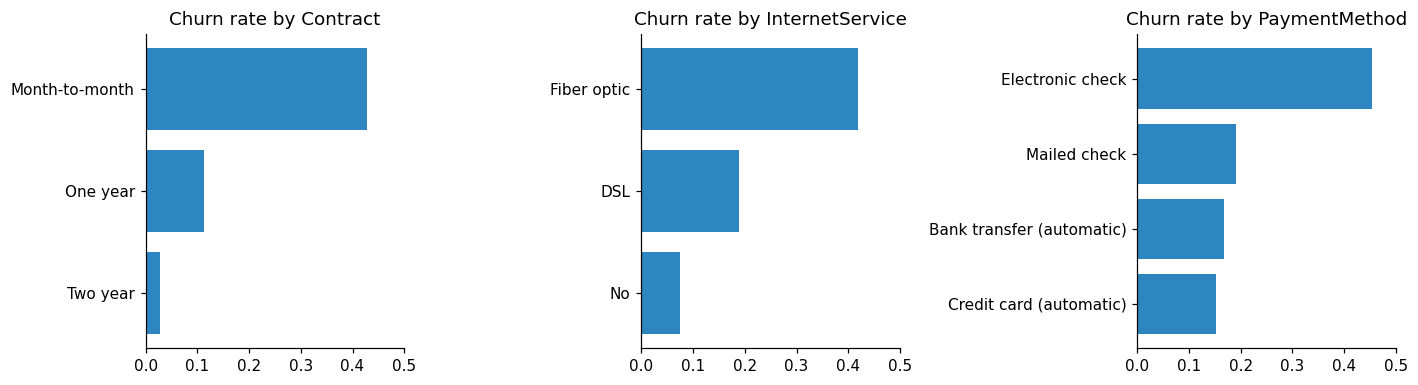

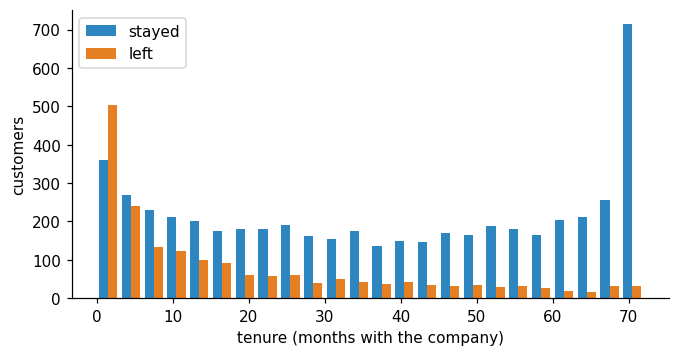

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]): #zip() pairs elements from two sequences.
    rate = left.groupby(churn[col]).mean().sort_values()
    ax.barh(rate.index, rate.values, color="#2E86C1")
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlim(0, 0.5)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist([churn.loc[~left, "tenure"], churn.loc[left, "tenure"]], bins=24, label=["stayed", "left"],
        color=["#2E86C1", "#E67E22"])
ax.set_xlabel("tenure (months with the company)")
ax.set_ylabel("customers")
ax.legend()
plt.show()

**What we see**
- **Month-to-month** customers leave far more often than customers on one- or two-year contracts.
- **Fibre-optic** customers and customers who pay by **electronic check** churn more.
- **New customers** (short tenure) are the most likely to leave.

A good model should discover these patterns by itself.

## 3. Prepare the data and build baselines

- The target `y` is 1 if the customer left.
- `customerID` is just a label: it carries no real signal, so we drop it.
- We keep **20% of customers as a test set**, with the same churn rate in both parts (`stratify=y`).

In [8]:
y = (churn["Churn"] == "Yes").astype(int)
X = churn.drop(columns=["customerID", "Churn"])
cat_cols = X.select_dtypes("object").columns.tolist()
num_cols = X.select_dtypes("number").columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print("train:", X_train.shape, "  test:", X_test.shape)
print(f"churn rate  train {y_train.mean():.3f}   test {y_test.mean():.3f}")
print(len(cat_cols), "category columns,", len(num_cols), "numeric columns")

train: (5634, 18)   test: (1409, 18)
churn rate  train 0.265   test 0.265
15 category columns, 3 numeric columns


Most models need numbers, so a **preprocessor** turns each category into 0/1 columns (one-hot encoding) and, for distance- and weight-based models, puts the numeric columns on the same scale. Putting the preprocessor **inside a pipeline** means it is refitted on the training part of every cross-validation fold, so no information leaks from the validation part.

In [9]:
def make_prep(scale=True):
    """One-hot encode the categories; optionally standardise the numbers."""
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", StandardScaler() if scale else "passthrough", num_cols)],
        verbose_feature_names_out=False)


print(make_prep().fit_transform(X_train).shape, "-> 18 columns become this many numbers")

(5634, 44) -> 18 columns become this many numbers


To compare models fairly we use **5-fold stratified cross-validation on the training set** and report three scores:
- **accuracy**: share of customers classified correctly;
- **ROC AUC**: how well the model *ranks* leavers above stayers (0.5 = guessing, 1 = perfect). This is our main score;
- **F1**: balances precision and recall for the "left" class.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results = {}


def evaluate(name, model, X=X_train, y=y_train, proba=True, fit_params=None):
    """5-fold CV scores for one model; the results are kept in `results` for a final comparison."""
    scoring = ["accuracy", "f1"] + (["roc_auc"] if proba else [])
    t = time.time()
    s = cross_validate(model, X, y, cv=cv, scoring=scoring, params=fit_params)
    r = {"accuracy": s["test_accuracy"].mean(), "F1": s["test_f1"].mean(),
         "ROC AUC": s["test_roc_auc"].mean() if proba else np.nan, "seconds": time.time() - t}
    results[name] = r
    auc = f"AUC {r['ROC AUC']:.3f} ± {s['test_roc_auc'].std():.3f}" if proba else "AUC   n/a      "
    print(f"{name:<26} accuracy {r['accuracy']:.3f}   {auc}   F1 {r['F1']:.3f}   ({r['seconds']:.1f}s)")

In [11]:
A = [1,2,3,4]
B = A+[]
print(A)
print(B)

[1, 2, 3, 4]
[1, 2, 3, 4]


In [12]:
evaluate("Always 'stays' (dummy)", DummyClassifier(strategy="most_frequent"))
evaluate("Logistic regression", make_pipeline(make_prep(), LogisticRegression(max_iter=1000)))
evaluate("k-nearest neighbours", make_pipeline(make_prep(), KNeighborsClassifier(n_neighbors=25)))
evaluate("Decision tree (depth 5)", make_pipeline(make_prep(False), DecisionTreeClassifier(max_depth=5, random_state=SEED)))
evaluate("Decision tree (no limit)", make_pipeline(make_prep(False), DecisionTreeClassifier(random_state=SEED)))

Always 'stays' (dummy)     accuracy 0.735   AUC 0.500 ± 0.000   F1 0.000   (0.1s)
Logistic regression        accuracy 0.801   AUC 0.845 ± 0.012   F1 0.589   (1.2s)
k-nearest neighbours       accuracy 0.788   AUC 0.831 ± 0.007   F1 0.593   (2.0s)
Decision tree (depth 5)    accuracy 0.792   AUC 0.830 ± 0.009   F1 0.567   (1.1s)
Decision tree (no limit)   accuracy 0.728   AUC 0.652 ± 0.013   F1 0.488   (2.3s)


**Read the results**
- The dummy model reaches about **73% accuracy while catching no leavers at all** (F1 = 0, AUC = 0.5). Accuracy alone can fool us.
- **Logistic regression** is a strong baseline here: churn depends fairly smoothly on contract type, tenure and charges.
- A **tree with no depth limit** memorises the training customers and does worst of the real models: high **variance**. Ensembles are built to fix exactly this.

## 4. Section A: why ensembles work
**Condorcet's jury theorem.** Suppose each voter (model) is right 70% of the time and the voters make their mistakes **independently**. How often is the **majority** right?

from scipy.stats import binom

A binomial distribution helps us calculate the probability of getting a certain number of successes in a fixed number of independent trials.

Imagine asking 11 people the same question, where each person has a 70% chance of giving the correct answer.

Each person's answer is a trial:

+ Success: the person answers correctly.

+ Failure: the person answers incorrectly.

The binom function helps us calculate the probability of different numbers of correct answers.

p = 0.70

This means each voter has a 70% probability of being correct and a 30% probability of being wrong.

For example, if 100 people vote, we would expect about 70 of them to be correct on average. However, the actual number could be higher or lower.

In [13]:
from scipy.stats import binom

p = 0.70
print(" voters   P(majority is right)")
for n in [1, 3, 5, 11, 25, 51]: #The group sizes are odd so that there cannot be a tie between the number of correct and incorrect votes.
    need = n // 2 + 1           # This calculates the minimum number of correct votes needed for a majority. The operator // means integer division, which discards the fractional part.
    print(f"{n:>6}   {1 - binom.cdf(need - 1, n, p):.3f}") #Calculate the probability. need - 1 = maximum number of successes that would still fail to meet the requirement.

 voters   P(majority is right)
     1   0.700
     3   0.784
     5   0.837
    11   0.922
    25   0.983
    51   0.999


binom.cdf(need - 1, n, p)

The cumulative distribution function (cdf) calculates the probability of getting at most a specified number of successes.

Its arguments are:

binom.cdf(number_of_successes, number_of_trials, probability_of_success)

For 11 voters:

binom.cdf(5, 11, 0.70)

This calculates the probability that 5 or fewer voters are correct.

But we want to know the probability that a majority is correct, meaning at least 6 voters are correct.

### Why subtract the result from 1?

The total probability of all possible outcomes is 1.

Therefore:

P(X≥6)=1−P(X≤5)

With independent voters the majority quickly becomes almost always right. But our models learn from **the same customers** with similar features, so they tend to make **the same mistakes**. Let's measure that with out-of-fold predictions (each customer is predicted by a model that never saw them).

### What is cross_val_predict()?

It generates a prediction for every training customer using a model that did not train on that particular customer.

Suppose you have 100 customers and use 5-fold cross-validation:

+ Divide the customers into 5 groups.

+ Train on 80 customers and predict the other 20.

+ Repeat until every customer has received a prediction from a model that excluded that customer during training.

This produces out-of-fold (OOF) predictions.


What is Out-of-Fold (OOF) Evaluation?

In standard K-Fold Cross-Validation, a dataset is split into K distinct "folds" (parts). The model trains on K-1 folds and validates on the remaining fold. This process repeats K times so that every data point is used for validation exactly once.
Out-of-Fold (OOF) predictions are the predictions made on each validation fold during this process.

Why do we need OOF?

If you evaluate a model's performance on the same data it was trained on, your performance metrics (like R² or Accuracy) will be overly optimistic. OOF predictions ensure that the prediction for any given row \(X_{i}\) is generated by a model that never saw \(X_{i}\) during training.

In [14]:
three = {
    "logistic": make_pipeline(make_prep(), LogisticRegression(max_iter=1000)),
    "knn": make_pipeline(make_prep(), KNeighborsClassifier(n_neighbors=25)),
    "tree": make_pipeline(make_prep(False), DecisionTreeClassifier(max_depth=5, random_state=SEED)),
}
oof = pd.DataFrame({name: cross_val_predict(m, X_train, y_train, cv=cv) for name, m in three.items()},
                   index=X_train.index)
wrong = oof.ne(y_train, axis=0)                       # True where a model is wrong
print("accuracy of each model:")
print((1 - wrong.mean()).round(3).to_string()) # Accuracy is the proportion of correct predictions, which is 1 minus the proportion of wrong predictions. The mean() function calculates the average of the boolean values in each column, giving the proportion of wrong predictions for each model. Subtracting this from 1 gives the accuracy. The round(3) function rounds the accuracy values to three decimal places, and to_string() converts the resulting Series to a string for display.
print("\ncorrelation of their mistakes:")
print(wrong.astype(int).corr().round(2))
majority = (oof.sum(axis=1) >= 2).astype(int) # Majority vote: predict 1 if at least 2 models predict 1
print(f"\nmajority vote accuracy: {accuracy_score(y_train, majority):.3f}")
print(f"all three wrong together on {wrong.all(axis=1).mean():.1%} of customers") # Proportion of customers on which all three models are wrong

accuracy of each model:
logistic    0.801
knn         0.788
tree        0.792

correlation of their mistakes:
          logistic   knn  tree
logistic      1.00  0.77  0.68
knn           0.77  1.00  0.64
tree          0.68  0.64  1.00

majority vote accuracy: 0.798
all three wrong together on 13.4% of customers


The mistakes are **strongly correlated**, so the majority vote gains little: the crowd is only wise when its members think differently. That is why ensemble methods work hard to create **diversity**: different algorithms (voting, stacking), different samples of the data (bagging), different features (random forests), or models that focus on earlier mistakes (boosting).

# Assignment

Find the customers that the models collectively wrongly classified.

## 5. Section B: voting and stacking
- **Hard voting:** each model votes for a class; the majority wins.
- **Soft voting:** average the predicted probabilities; usually better when the probabilities are sensible.
- **Stacking:** a *meta-model* learns how much to trust each base model, using their out-of-fold predictions.

In [15]:
from sklearn.ensemble import StackingClassifier, VotingClassifier

base = list(three.items())
evaluate("Hard voting (3 models)", VotingClassifier(base, voting="hard"), proba=False)
evaluate("Soft voting (3 models)", VotingClassifier(base, voting="soft"))
evaluate("Stacking (3 models)", StackingClassifier(base, final_estimator=LogisticRegression(), cv=5))

Hard voting (3 models)     accuracy 0.798   AUC   n/a         F1 0.594   (2.5s)
Soft voting (3 models)     accuracy 0.800   AUC 0.847 ± 0.008   F1 0.590   (3.7s)
Stacking (3 models)        accuracy 0.803   AUC 0.847 ± 0.009   F1 0.583   (12.7s)


Hard voting has no probabilities, so it has no AUC. Compare with the single models above: on this data the combined models are **about as good as logistic regression on its own**, not clearly better. That is an honest and common result: when one model is already strong and the others make the same mistakes, voting cannot help much. The stacker's weights show which models it trusts:

In [16]:
stack = StackingClassifier(base, final_estimator=LogisticRegression(), cv=5).fit(X_train, y_train)
print(pd.Series(stack.final_estimator_.coef_[0], index=[n for n, _ in base]).round(2).to_string())

logistic    2.72
knn         1.65
tree        1.41


## 6. Section C: bagging and random forests
**Bootstrap sample:** draw *n* rows **with replacement** from *n* rows. Some rows appear twice or more, and about **63%** of the distinct rows are used. The rest (about 37%) are "out of bag".

In [17]:
X_train.shape

(5634, 18)

In [18]:
rng = np.random.default_rng(SEED)
n = len(X_train)
for i in range(3):
    rows = rng.integers(0, n, size=n)                 # one bootstrap sample of row numbers
    print(f"sample {i + 1}: {len(np.unique(rows)) / n:.1%} of the customers used")
print(f"theory: 1 - (1 - 1/n)^n = {1 - (1 - 1 / n) ** n:.1%}")

sample 1: 62.9% of the customers used
sample 2: 63.4% of the customers used
sample 3: 63.1% of the customers used
theory: 1 - (1 - 1/n)^n = 63.2%


**Bagging** trains one deep tree on each bootstrap sample and lets them vote. A **random forest** also lets each split consider only a random subset of features, which makes the trees more different from each other. **Extra trees** go further and choose split points at random.

In [19]:
from sklearn.ensemble import BaggingClassifier, ExtraTreesClassifier, RandomForestClassifier

tree_prep = make_prep(scale=False)                   # trees do not need scaling
evaluate("Bagging (200 trees)", make_pipeline(tree_prep, BaggingClassifier(
    DecisionTreeClassifier(), n_estimators=200, random_state=SEED, n_jobs=-1)))
evaluate("Random forest (default)", make_pipeline(tree_prep, RandomForestClassifier(
    n_estimators=300, random_state=SEED, n_jobs=-1)))
evaluate("Extra trees (default)", make_pipeline(tree_prep, ExtraTreesClassifier(
    n_estimators=300, random_state=SEED, n_jobs=-1)))

Bagging (200 trees)        accuracy 0.784   AUC 0.819 ± 0.012   F1 0.544   (23.8s)
Random forest (default)    accuracy 0.783   AUC 0.814 ± 0.013   F1 0.541   (10.3s)
Extra trees (default)      accuracy 0.762   AUC 0.779 ± 0.016   F1 0.505   (10.8s)


200 trees voting are far better than one unlimited tree (AUC about 0.65 → 0.80 or more): **bagging reduces variance**. But the forests still use fully grown trees that memorise noise. On noisy data like churn, asking each leaf to hold at least a few customers (`min_samples_leaf`) helps a lot:

In [20]:
for leaf in [1, 5, 20, 50]:
    rf = make_pipeline(tree_prep, RandomForestClassifier(
        n_estimators=300, min_samples_leaf=leaf, random_state=SEED, n_jobs=-1))
    auc = cross_validate(rf, X_train, y_train, cv=cv, scoring="roc_auc")["test_score"].mean()
    print(f"min_samples_leaf = {leaf:>2}   CV AUC {auc:.3f}")

min_samples_leaf =  1   CV AUC 0.814
min_samples_leaf =  5   CV AUC 0.843
min_samples_leaf = 20   CV AUC 0.846
min_samples_leaf = 50   CV AUC 0.844


In [21]:
evaluate("Random forest (leaf 20)", make_pipeline(tree_prep, RandomForestClassifier(
    n_estimators=300, min_samples_leaf=20, random_state=SEED, n_jobs=-1)))

Random forest (leaf 20)    accuracy 0.801   AUC 0.846 ± 0.009   F1 0.559   (6.3s)


### The out-of-bag (OOB) score: a free test
Each tree never saw about 37% of the customers, so those trees can be graded on them. Averaged over the forest this gives a validation score **without a separate validation set**.

In [22]:
Xt_train = tree_prep.fit_transform(X_train)          # numbers the forest can use
feature_names = tree_prep.get_feature_names_out()
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, oob_score=True,
                            random_state=SEED, n_jobs=-1).fit(Xt_train, y_train)
oob_auc = roc_auc_score(y_train, rf.oob_decision_function_[:, 1])
print(f"OOB accuracy {rf.oob_score_:.3f}    OOB AUC {oob_auc:.3f}")
print(f"5-fold CV    {results['Random forest (leaf 20)']['accuracy']:.3f}             "
      f"{results['Random forest (leaf 20)']['ROC AUC']:.3f}")

OOB accuracy 0.802    OOB AUC 0.846
5-fold CV    0.801             0.846


The OOB scores agree closely with cross-validation, at a fraction of the cost. How many trees do we need? Watch the OOB error settle as trees are added:

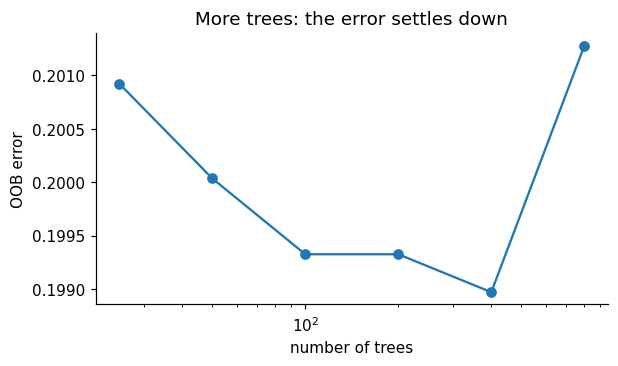

In [23]:
sizes = [25, 50, 100, 200, 400, 800]
errors = []
forest = RandomForestClassifier(warm_start=True, min_samples_leaf=20, oob_score=True,
                                random_state=SEED, n_jobs=-1)
for k in sizes:
    forest.set_params(n_estimators=k).fit(Xt_train, y_train)   # warm_start adds trees
    errors.append(1 - forest.oob_score_)
plt.figure(figsize=(6, 3.2))
plt.plot(sizes, errors, "o-")
plt.xscale("log")
plt.xlabel("number of trees")
plt.ylabel("OOB error")
plt.title("More trees: the error settles down")
plt.show()

### Which features matter?
- **Impurity importance** (built into the forest): fast, but it favours numeric columns with many possible split points.
- **Permutation importance:** shuffle one column in held-out data and measure how much the score drops. It is slower but more trustworthy, and with a pipeline it works on the **original** columns.

We hold out 20% of the *training* set for this (the test set stays locked).

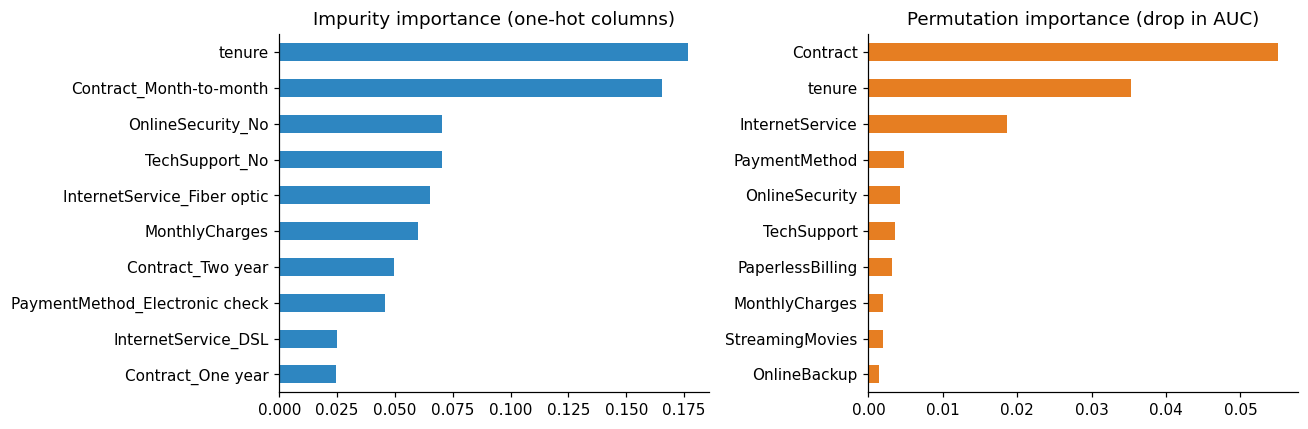

In [24]:
from sklearn.inspection import permutation_importance

X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2,
                                              stratify=y_train, random_state=SEED)
rf_pipe = make_pipeline(make_prep(scale=False), RandomForestClassifier(
    n_estimators=300, min_samples_leaf=20, random_state=SEED, n_jobs=-1)).fit(X_fit, y_fit)
forest = rf_pipe[-1]
impurity = pd.Series(forest.feature_importances_, index=rf_pipe[0].get_feature_names_out()).nlargest(10)
perm = permutation_importance(rf_pipe, X_val, y_val, scoring="roc_auc", n_repeats=10, random_state=SEED)
permutation = pd.Series(perm.importances_mean, index=X_val.columns).nlargest(10)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
impurity[::-1].plot.barh(ax=axes[0], color="#2E86C1", title="Impurity importance (one-hot columns)")
permutation[::-1].plot.barh(ax=axes[1], color="#E67E22", title="Permutation importance (drop in AUC)")
plt.tight_layout()
plt.show()

Both views agree on the big story: **contract type**, **tenure**, **internet service** (fibre) and **charges** drive churn, matching what we saw when exploring. Permutation importance is reported for whole original columns, which is easier to explain to a manager.

## 7. Section D: boosting with AdaBoost
Bagging trains trees **independently**; boosting trains them **one after another**, each one concentrating on the customers the previous ones got wrong. AdaBoost uses **stumps** (trees with one split):
1. Start with equal weights for all customers.
2. Fit a stump; compute its weighted error ε and its "say" α = ½·ln((1 − ε)/ε).
3. Increase the weights of the customers it got wrong, decrease the others, and repeat.

Here are the first three rounds on the churn training data. For a 0/1 column such as `Contract_Month-to-month`, "≤ 0.5" means "No".

In [25]:
def says(stump, leaf):
    """What a stump predicts in one of its two leaves (1 = left, 2 = right)."""
    counts = stump.tree_.value[leaf][0]
    return "leaves" if counts[1] > counts[0] else "stays"


yy = y_train.to_numpy()
w = np.full(len(yy), 1 / len(yy))                     # step 1: equal weights
for t in range(1, 4):
    stump = DecisionTreeClassifier(max_depth=1).fit(Xt_train, yy, sample_weight=w)
    miss = stump.predict(Xt_train) != yy
    err = w[miss].sum()                                # weighted error
    alpha = 0.5 * np.log((1 - err) / err)              # the stump's say
    f, thr = stump.tree_.feature[0], stump.tree_.threshold[0]
    print(f"round {t}: if {feature_names[f]} <= {thr:.1f} -> {says(stump, 1)}, else -> {says(stump, 2)}")
    print(f"         weighted error {err:.3f}   say α = {alpha:.3f}")
    w = w * np.exp(np.where(miss, alpha, -alpha))      # wrong -> heavier, right -> lighter
    w = w / w.sum()
    print(f"         a misclassified customer now weighs {w[miss][0] / w[~miss][0]:.1f}x a correct one")

round 1: if Contract_Month-to-month <= 0.5 -> stays, else -> stays
         weighted error 0.265   say α = 0.509
         a misclassified customer now weighs 2.8x a correct one
round 2: if Contract_Month-to-month <= 0.5 -> stays, else -> leaves
         weighted error 0.271   say α = 0.495
         a misclassified customer now weighs 2.7x a correct one
round 3: if InternetService_Fiber optic <= 0.5 -> stays, else -> leaves
         weighted error 0.355   say α = 0.300
         a misclassified customer now weighs 1.8x a correct one


Look closely at **round 1**. Even month-to-month customers leave less than half the time (43%), so with equal weights the best stump predicts **"stays" for everyone**. Its error is simply the churn rate. AdaBoost then makes every leaver about 3 times heavier. In **round 2** the same question now flags month-to-month customers as leavers, and round 3 moves on to a new question (fibre internet). **Each round focuses on the customers the earlier rounds got wrong.**

Scikit-learn does all of this for us. How many stumps do we need?

  1 stumps   train AUC 0.500   validation AUC 0.500
  5 stumps   train AUC 0.785   validation AUC 0.778
 20 stumps   train AUC 0.842   validation AUC 0.839
100 stumps   train AUC 0.851   validation AUC 0.846
500 stumps   train AUC 0.855   validation AUC 0.849


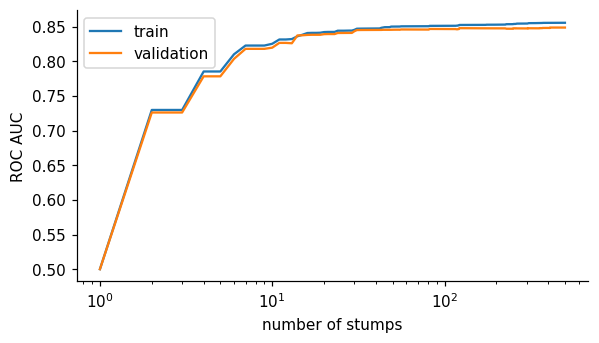

In [26]:
from sklearn.ensemble import AdaBoostClassifier

Xt_fit, Xt_val = Xt_train[X_train.index.get_indexer(X_fit.index)], Xt_train[X_train.index.get_indexer(X_val.index)]
ada = AdaBoostClassifier(n_estimators=500, learning_rate=0.5, random_state=SEED).fit(Xt_fit, y_fit)
train_auc = [roc_auc_score(y_fit, p[:, 1]) for p in ada.staged_predict_proba(Xt_fit)]
val_auc = [roc_auc_score(y_val, p[:, 1]) for p in ada.staged_predict_proba(Xt_val)]
for k in [1, 5, 20, 100, 500]:
    print(f"{k:>3} stumps   train AUC {train_auc[k - 1]:.3f}   validation AUC {val_auc[k - 1]:.3f}")

plt.figure(figsize=(6, 3.2))
plt.plot(range(1, 501), train_auc, label="train")
plt.plot(range(1, 501), val_auc, label="validation")
plt.xscale("log")
plt.xlabel("number of stumps")
plt.ylabel("ROC AUC")
plt.legend()
plt.show()

One stump cannot rank customers at all (AUC 0.5, as we saw in round 1), but a few dozen boosted stumps are already competitive with our best models. (The data was one-hot encoded once on the whole training set here only to keep the demo short; for scoring we always use pipelines.)

In [27]:
evaluate("AdaBoost (200 stumps)", make_pipeline(make_prep(False), AdaBoostClassifier(
    n_estimators=200, learning_rate=0.5, random_state=SEED)))

AdaBoost (200 stumps)      accuracy 0.803   AUC 0.848 ± 0.012   F1 0.591   (7.0s)


## 8. Section E: gradient boosting
Gradient boosting is like golf: each new small tree is fitted to the **remaining error** of the model so far (the gradient of the loss) and moves the prediction a small step (the **learning rate**) closer to the hole. Notebook 3 does it by hand for a regression problem; here we look at the two key settings: **learning rate** and **number of trees**.

learning rate 1.0   best validation log loss 0.4303 after 4 trees
learning rate 0.3   best validation log loss 0.4087 after 19 trees
learning rate 0.1   best validation log loss 0.4100 after 77 trees
learning rate 0.03  best validation log loss 0.4100 after 218 trees


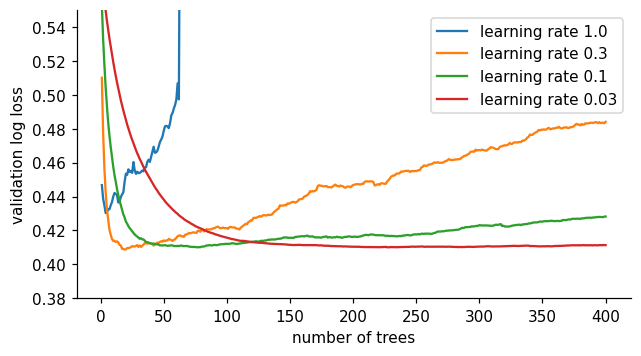

In [28]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import log_loss

plt.figure(figsize=(6.5, 3.4))
for lr in [1.0, 0.3, 0.1, 0.03]:
    gb = GradientBoostingClassifier(n_estimators=400, learning_rate=lr, max_depth=3,
                                    random_state=SEED).fit(Xt_fit, y_fit)
    losses = [log_loss(y_val, p[:, 1]) for p in gb.staged_predict_proba(Xt_val)]
    best = int(np.argmin(losses))
    plt.plot(range(1, 401), losses, label=f"learning rate {lr}")
    print(f"learning rate {lr:<4}  best validation log loss {losses[best]:.4f} after {best + 1} trees")
plt.ylim(0.38, 0.55)
plt.xlabel("number of trees")
plt.ylabel("validation log loss")
plt.legend()
plt.show()

- A **large** learning rate learns fast and then **overfits**: the validation loss goes back up.
- A **small** learning rate needs many more trees but usually ends at a similar or better score.

So we should not guess the number of trees: **early stopping** watches a validation set and stops when it stops improving.

In [29]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb = HistGradientBoostingClassifier(max_iter=1000, learning_rate=0.05, early_stopping=True,
                                     validation_fraction=0.15, n_iter_no_change=30, random_state=SEED)
hgb.fit(Xt_fit, y_fit)
print("trees actually built:", hgb.n_iter_, "of 1000 allowed")
print(f"validation AUC: {roc_auc_score(y_val, hgb.predict_proba(Xt_val)[:, 1]):.3f}")

trees actually built: 82 of 1000 allowed
validation AUC: 0.843


### XGBoost, LightGBM and CatBoost
Three popular libraries make gradient boosting faster and add regularisation:
- **XGBoost:** regularised trees, row and column sampling, early stopping on a validation set.
- **LightGBM:** very fast; grows trees leaf by leaf and handles **category columns natively**.
- **CatBoost:** takes the **raw text categories** directly ("Month-to-month", "Fiber optic"...).

In [30]:
from xgboost import XGBClassifier

xgb = XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=3, subsample=0.8,
                    colsample_bytree=0.8, eval_metric="auc", early_stopping_rounds=50,
                    random_state=SEED)
xgb.fit(Xt_fit, y_fit, eval_set=[(Xt_val, y_val)], verbose=False)
print("best number of trees:", xgb.best_iteration + 1)
print(f"XGBoost validation AUC: {roc_auc_score(y_val, xgb.predict_proba(Xt_val)[:, 1]):.3f}")

best number of trees: 125
XGBoost validation AUC: 0.854


In [31]:
from lightgbm import LGBMClassifier

X_cat = X.astype({c: "category" for c in cat_cols})  # same categories for every row
lgbm = LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=40,
                      random_state=SEED, verbose=-1)
lgbm.fit(X_cat.loc[X_fit.index], y_fit)
print(f"LightGBM validation AUC: {roc_auc_score(y_val, lgbm.predict_proba(X_cat.loc[X_val.index])[:, 1]):.3f}")

LightGBM validation AUC: 0.848


In [32]:
from catboost import CatBoostClassifier

cat = CatBoostClassifier(iterations=500, learning_rate=0.05, depth=4, random_seed=SEED,
                         verbose=0, allow_writing_files=False)
cat.fit(X_fit, y_fit, cat_features=cat_cols)          # raw text categories!
print(f"CatBoost validation AUC: {roc_auc_score(y_val, cat.predict_proba(X_val)[:, 1]):.3f}")

CatBoost validation AUC: 0.852


### Head to head (5-fold cross-validation on the training set)

In [33]:
evaluate("Gradient boosting (sklearn)", make_pipeline(make_prep(False), GradientBoostingClassifier(
    n_estimators=150, learning_rate=0.05, max_depth=3, random_state=SEED)))
evaluate("HistGradientBoosting", make_pipeline(make_prep(False), HistGradientBoostingClassifier(
    learning_rate=0.05, max_iter=200, max_depth=3, random_state=SEED)))
evaluate("XGBoost", make_pipeline(make_prep(False), XGBClassifier(
    n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.8,
    random_state=SEED)))
evaluate("LightGBM", LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15,
                                    min_child_samples=40, random_state=SEED, verbose=-1),
         X=X_cat.loc[X_train.index])
evaluate("CatBoost", CatBoostClassifier(iterations=500, learning_rate=0.05, depth=4, random_seed=SEED,
                                        verbose=0, allow_writing_files=False),
         fit_params={"cat_features": cat_cols})       # passed on to CatBoost's fit()

Gradient boosting (sklearn) accuracy 0.805   AUC 0.849 ± 0.011   F1 0.590   (6.8s)
HistGradientBoosting       accuracy 0.804   AUC 0.848 ± 0.012   F1 0.586   (2.8s)
XGBoost                    accuracy 0.805   AUC 0.850 ± 0.011   F1 0.588   (1.9s)
LightGBM                   accuracy 0.803   AUC 0.844 ± 0.010   F1 0.587   (1.4s)
CatBoost                   accuracy 0.805   AUC 0.848 ± 0.011   F1 0.585   (23.4s)


### Opening the black box with SHAP
A boosted model is hard to read directly. **SHAP values** split each prediction into contributions from each feature: positive values push the churn risk **up**, negative values push it **down**.

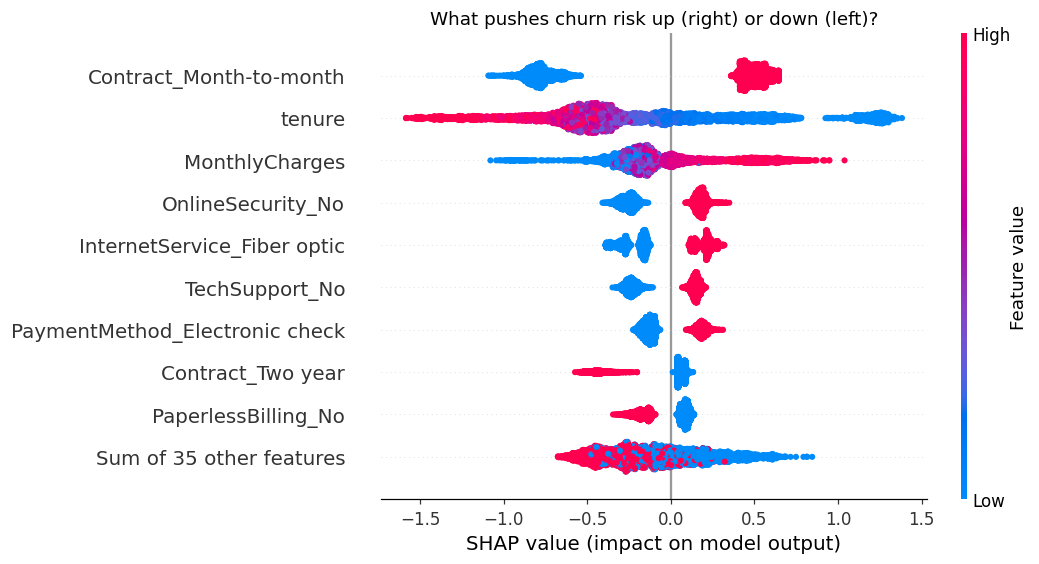

In [34]:
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")   # harmless notice outside Colab
import shap

booster = XGBClassifier(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8,
                        colsample_bytree=0.8, random_state=SEED).fit(Xt_train, y_train)
Xt_df = pd.DataFrame(Xt_train, columns=feature_names)
sv = shap.TreeExplainer(booster)(Xt_df)
shap.plots.beeswarm(sv, max_display=10, show=False)
plt.title("What pushes churn risk up (right) or down (left)?")
plt.show()

Each dot is one customer. Red means a high value of that feature. For example, being on a **month-to-month contract** (red, `Contract_Month-to-month` = 1) pushes the risk up, while **long tenure** (red) pushes it down. SHAP can also explain **one customer**, which is what the retention team needs on the phone:

predicted churn risk: 94.2%


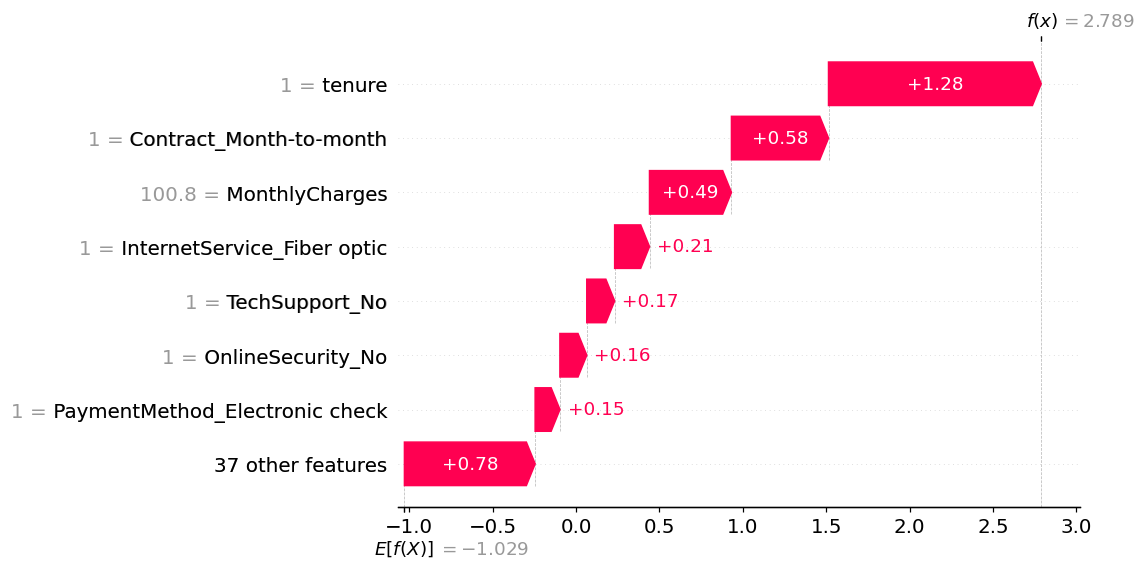

In [35]:
risky = int(np.argmax(booster.predict_proba(Xt_train)[:, 1]))   # the highest-risk customer
print(f"predicted churn risk: {booster.predict_proba(Xt_train[[risky]])[0, 1]:.1%}")
shap.plots.waterfall(sv[risky], max_display=8, show=False)
plt.show()

## 9. Which ensemble should I try? The scoreboard

In [36]:
board = pd.DataFrame(results).T.sort_values("ROC AUC", ascending=False)
board.round(3)

,accuracy,F1,ROC AUC,seconds
XGBoost,0.805,0.588,0.850,1.894
Gradient boosting (sklearn),0.805,0.590,0.849,6.834
CatBoost,0.805,0.585,0.848,23.390
AdaBoost (200 stumps),0.803,0.591,0.848,7.034
HistGradientBoosting,0.804,0.586,0.848,2.832
Stacking (3 models),0.803,0.583,0.847,12.749
Soft voting (3 models),0.800,0.590,0.847,3.656
Random forest (leaf 20),0.801,0.559,0.846,6.277
Logistic regression,0.801,0.589,0.845,1.233
LightGBM,0.803,0.587,0.844,1.447


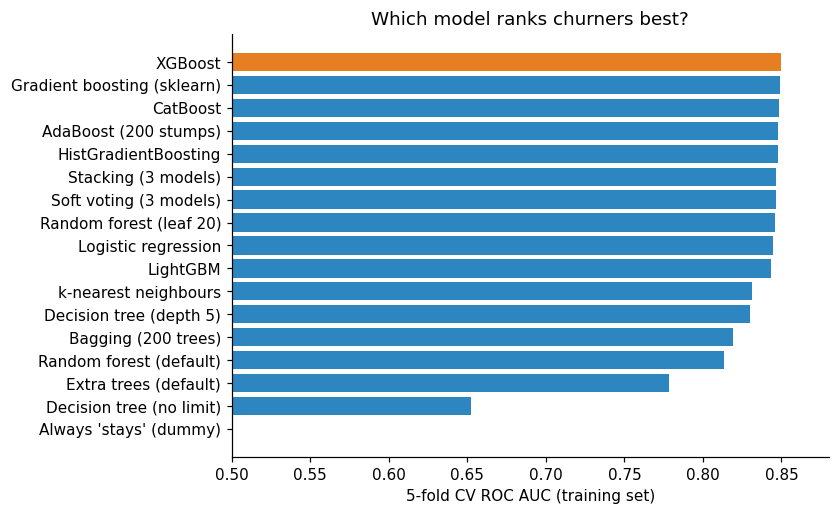

In [37]:
top = board["ROC AUC"].dropna().sort_values()
plt.figure(figsize=(7, 5))
plt.barh(top.index, top.values, color=["#E67E22" if v == top.max() else "#2E86C1" for v in top.values])
plt.xlim(0.5, 0.88)
plt.xlabel("5-fold CV ROC AUC (training set)")
plt.title("Which model ranks churners best?")
plt.show()

**What the scoreboard tells us**
1. The **boosted models** (gradient boosting, XGBoost, CatBoost, AdaBoost) are at the top, followed closely by stacking, soft voting and the **regularised random forest**. But **all the sensible models are within about 0.005 AUC of each other**, and **logistic regression** is only a whisker behind. On tabular data with a few strong, smooth signals (contract, tenure, charges), a simple model can be very competitive. Always keep a simple baseline.
2. Unlimited trees, alone or bagged, overfit. **Regularise** trees (`min_samples_leaf`, `max_depth`, learning rate, early stopping).
3. Differences of 0.002–0.005 AUC are within the fold-to-fold noise (the ± values). Do not crown a winner on such a small gap; prefer the simpler or faster model.
4. Speed matters too: compare the `seconds` column.

